# Proctoring: fine-tune YOLO26n nhận diện vật thể (7 class) — bản chạy trên Kaggle

Notebook chạy trọn quy trình trên Kaggle (GPU T4 x2 hoặc P100): tải và gộp dataset từ Roboflow, train, đánh giá, vẽ biểu đồ, export ONNX.

**7 class:** `person, book, cell phone, laptop, tv, headphone, smartwatch`

**Chuẩn bị trên Kaggle (panel Settings bên phải):**
1. **Accelerator** → GPU T4 x2 (nếu dùng P100 mà báo lỗi CUDA/kernel thì đổi sang T4).
2. **Internet** → On (cần xác minh số điện thoại cho tài khoản). Bắt buộc để tải dataset Roboflow và trọng số pretrained.
3. **Add-ons → Secrets** → thêm secret tên `ROBOFLOW_API_KEY`, nhớ tick *Attached*.

**Cách dùng:** chạy lần lượt từ trên xuống. Lần đầu nên đặt `QUICK_TEST = True` (ô cấu hình) để chạy thử 2 epoch trên 10% dữ liệu, kiểm tra pipeline không lỗi rồi mới train thật. Train thật nên dùng **Save Version → Save & Run All (Commit)** để notebook chạy nền, không bị ngắt khi đóng trình duyệt.

**Lưu ý lưu trữ:** kết quả (weights, biểu đồ, CSV, ONNX) nằm ở `/kaggle/working/CV/output` và tải được ở tab Output. Dataset gộp (nhiều ảnh) để ở `/kaggle/temp` nên không bị tính vào Output.


## 1. Cài đặt

In [12]:
!pip install -q -U ultralytics roboflow pyyaml

import os, sys, urllib.request

os.environ["WANDB_MODE"] = "disabled"   # tránh bị hỏi đăng nhập wandb

# Kiểm tra Internet (phải bật ở Settings > Internet > On)
try:
    urllib.request.urlopen("https://github.com", timeout=10)
    print("Internet: OK")
except Exception:
    print("KHÔNG CÓ INTERNET: bật Settings > Internet > On rồi chạy lại từ đầu")

# API key Roboflow: Add-ons > Secrets > secret tên ROBOFLOW_API_KEY (tick Attached)
try:
    from kaggle_secrets import UserSecretsClient
    os.environ["ROBOFLOW_API_KEY"] = UserSecretsClient().get_secret("ROBOFLOW_API_KEY")
except Exception:
    from getpass import getpass
    os.environ["ROBOFLOW_API_KEY"] = getpass("Dán Roboflow API key: ")

import torch
if torch.cuda.is_available():
    for i in range(torch.cuda.device_count()):
        print(f"GPU {i}:", torch.cuda.get_device_name(i))
    if torch.cuda.get_device_capability(0) < (7, 0):
        print("Cảnh báo: GPU đời cũ (P100). Nếu train báo lỗi 'no kernel image', đổi Accelerator sang GPU T4 x2.")
else:
    print("KHÔNG CÓ GPU: Settings > Accelerator > GPU T4 x2 rồi chạy lại từ đầu")


Internet: OK
GPU 0: Tesla T4
GPU 1: Tesla T4


In [13]:
QUICK_TEST = False        # True: chạy thử 2 epoch trên 10% dữ liệu để kiểm tra pipeline
MODELS = ["yolo26n.pt"]   # thêm "yolo11n.pt", "yolov8n.pt" để so sánh nhiều model (biểu đồ 14)
EPOCHS = 80
IMGSZ = 640
BATCH = 16
RETRAIN = False           # False: nếu đã có best.pt thì bỏ qua bước train
CACHE = True              # cache ảnh vào RAM cho train nhanh; đặt False nếu bị tràn RAM
SAVE_ZIP_BACKUP = True    # lưu merged_dataset.zip vào Output để lần sau upload thành Kaggle Dataset
DEVICE = 0 if torch.cuda.is_available() else "cpu"   # dùng 1 GPU cho ổn định; đa GPU: DEVICE = [0, 1]
WORKERS = 4               # Kaggle có 4 CPU

# /kaggle/working: giữ lại thành Output (giới hạn 20 GB). /kaggle/temp: tạm, không tính vào Output.
OUT_DIR = "/kaggle/working/CV/output"
TEMP_DIR = "/kaggle/temp"
try:
    os.makedirs(TEMP_DIR, exist_ok=True)
except OSError:
    TEMP_DIR = "/kaggle/working/_tmp"
    os.makedirs(TEMP_DIR, exist_ok=True)
os.environ["TEMP_DIR"] = TEMP_DIR          # build_merged_dataset.py đọc biến này

INPUT_DIR = "/kaggle/input"
MERGED_DIR = f"{TEMP_DIR}/merged_dataset"
ZIP_BACKUP = "/kaggle/working/merged_dataset.zip"
SUFFIX = "_quick" if QUICK_TEST else ""
CHART_DIR = f"{OUT_DIR}/charts{SUFFIX}"
os.makedirs(CHART_DIR, exist_ok=True)


## 2. Tải và gộp dataset

Ô đầu ghi file `build_merged_dataset.py` (danh sách nguồn dataset nằm trong biến `SOURCES`, sửa tại đây nếu muốn thêm hoặc bớt nguồn). Ô sau chạy gộp, rồi lưu bản zip vào `/kaggle/working`. Muốn dùng lại ở các lần chạy sau, tải zip từ tab Output, upload thành Kaggle Dataset rồi Add Input: notebook sẽ tự tìm thấy.

Lưu ý: nếu bản zip cũ được tạo từ Colab khi class `smartwatch` chưa có ảnh nào (do lỗi alias), đừng dùng lại, hãy để notebook gộp lại từ đầu.


In [14]:
%%writefile build_merged_dataset.py
"""
build_merged_dataset.py
Tải nhiều dataset Roboflow rồi gộp về 7 class thống nhất (định dạng YOLO).

Chạy trên Kaggle (bật Internet, thêm secret ROBOFLOW_API_KEY):
    !pip install -q roboflow pyyaml
    !python build_merged_dataset.py

Kết quả: $TEMP_DIR/merged_dataset/{train,valid,test}/{images,labels} + data.yaml
(TEMP_DIR mặc định /kaggle/temp)
"""
import math
import os
import random
import shutil
from collections import Counter
from pathlib import Path

import yaml

# ============================== CẤU HÌNH ==============================
ROBOFLOW_API_KEY = os.environ.get("ROBOFLOW_API_KEY", "YOUR_API_KEY")
TEMP_DIR = Path(os.environ.get("TEMP_DIR", "/kaggle/temp"))
WORK_DIR = TEMP_DIR / "datasets"            # nơi tải các dataset gốc
OUT_DIR = TEMP_DIR / "merged_dataset"       # dataset sau khi gộp
SEED = 42
KEEP_EMPTY = False  # True = giữ cả ảnh không còn nhãn nào (làm ảnh nền/background)

UNIFIED_CLASSES = [
    "person", "book", "cell phone", "laptop",
    "tv", "headphone", "smartwatch",
]

# Tên class trong từng dataset khác nhau -> quy về class thống nhất.
# Tên không có trong bảng này sẽ bị BỎ và script in cảnh báo.
# LƯU Ý: khóa phải viết THƯỜNG hết (code so khớp sau khi .lower()), không được trùng khóa.
ALIASES = {
    "person": "person", "people": "person",
    "book": "book", "books": "book",
    "cell phone": "cell phone", "cellphone": "cell phone", "mobile phone": "cell phone",
    "mobilephone": "cell phone", "phone": "cell phone", "smartphone": "cell phone",
    "laptop": "laptop", "loptop": "laptop",
    "tv": "tv", "television": "tv",
    "headphone": "headphone", "headphones": "headphone",
    "smartwatch": "smartwatch", "smartwatch-detection": "smartwatch", "Smart_watch": "smartwatch",
    "smart watch": "smartwatch", "smart-watch": "smartwatch", "smartwatches": "smartwatch",
    "watch": "smartwatch", "wristwatch": "smartwatch",
}

# rf = (workspace, project, version). Số version xem ở trang dataset trên Universe.
# max_images = giới hạn số ảnh train lấy từ nguồn đó (tránh một nguồn lấn át các nguồn khác).
SOURCES = [
    # --- Dataset nền (đã có 6 class) ---
    dict(tag="proctor", rf=("online-exam-cheating-detection-kvdul", "online-proctoring-system-x27ou-e7abr", 1),
         max_images=None),

    # --- smartwatch: 3 dataset do bạn chọn. Số version (số cuối) để 1; nếu tải lỗi,
    #     mở trang dataset trên Universe, xem số version rồi sửa lại. ---
    #     force_class: ép MỌI class của nguồn đó về một class thống nhất (dùng cho dataset 1 class).
    dict(tag="sw_kishor", rf=("kishor-cj8ys", "smartwatch-detection-rh433", 1), max_images=1000,
         force_class="smartwatch"),
    dict(tag="sw_vignesh",rf=("vignesh", "qewcfwe", 4),max_images=None),
    dict(tag="sw_nsg",rf=("veereshg9921-gmail-com", "nsg", 3),max_images=None,only_classes=["Smart_watch"]),
    dict(tag="sw_shakoor",rf=("m-shakoor", "smartwatch-dataset-ge3vf", 1),max_images=None,only_classes=["smartwatch"]),
    # --- Nguồn "watch" chung (có thể gồm cả đồng hồ cơ), bỏ comment nếu muốn thêm ảnh ---
    # dict(tag="watch_d110", rf=("d110", "watch-yhzpo", 2), max_images=1200),   # 1150 ảnh

    # --- Dataset đã Add Input trên Kaggle thì khai báo kiểu này ---
    # dict(tag="my_own", local="/kaggle/input/ten-dataset-cua-ban", max_images=None),
]
# ======================================================================

SPLITS = {"train": ["train"], "valid": ["valid", "val", "validation"], "test": ["test"]}
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}


def download_roboflow(ws, proj, ver, dest: Path) -> bool:
    if "TODO" in proj:
        print(f"  [bỏ qua] chưa điền slug project cho workspace '{ws}'")
        return False
    if dest.exists() and any(dest.iterdir()):
        print(f"  [đã có] {dest}")
        return True
    try:
        from roboflow import Roboflow
        rf = Roboflow(api_key=ROBOFLOW_API_KEY)
        rf.workspace(ws).project(proj).version(ver).download("yolov8", location=str(dest))
        return True
    except Exception as e:  # sai slug/version, không có quyền... thì bỏ qua nguồn này
        print(f"  [lỗi tải] {ws}/{proj} v{ver}: {e}")
        return False


def load_names(root: Path):
    cfg = yaml.safe_load(open(root / "data.yaml", encoding="utf-8"))
    names = cfg["names"]
    if isinstance(names, dict):
        return [names[k] for k in sorted(names)]
    return list(names)


def find_split_dirs(root: Path, split: str):
    """Hỗ trợ cả hai layout: split/images + split/labels  và  images/split + labels/split."""
    for name in SPLITS[split]:
        for img_d, lbl_d in ((root / name / "images", root / name / "labels"),
                             (root / "images" / name, root / "labels" / name)):
            if img_d.is_dir():
                return img_d, lbl_d
    return None, None


def convert_line(line: str, id_map: dict):
    """Chuyển 1 dòng nhãn sang bbox YOLO với ID mới. Dòng polygon -> bbox bao ngoài."""
    parts = line.split()
    if len(parts) < 5:
        return None
    try:
        old = int(float(parts[0]))
        vals = [float(v) for v in parts[1:]]
    except ValueError:
        return None
    if old not in id_map:
        return None
    if len(vals) == 4:
        x, y, w, h = vals
    elif len(vals) >= 6 and len(vals) % 2 == 0:  # polygon (lỗi "mix segment and detection")
        xs, ys = vals[0::2], vals[1::2]
        x0, x1, y0, y1 = min(xs), max(xs), min(ys), max(ys)
        x, y, w, h = (x0 + x1) / 2, (y0 + y1) / 2, x1 - x0, y1 - y0
    else:
        return None
    x0, x1 = max(0.0, x - w / 2), min(1.0, x + w / 2)
    y0, y1 = max(0.0, y - h / 2), min(1.0, y + h / 2)
    w, h = x1 - x0, y1 - y0
    if w <= 0 or h <= 0:
        return None
    return f"{id_map[old]} {(x0 + x1) / 2:.6f} {(y0 + y1) / 2:.6f} {w:.6f} {h:.6f}"


def build_id_map(tag: str, names: list, force_class=None):
    id_map, dropped = {}, []
    for i, n in enumerate(names):
        target = force_class or ALIASES.get(str(n).strip().lower())
        if target:
            id_map[i] = UNIFIED_CLASSES.index(target)
        else:
            dropped.append(n)
    print(f"  class gốc: {names}")
    print(f"  -> giữ: { {names[i]: UNIFIED_CLASSES[j] for i, j in id_map.items()} }")
    if dropped:
        print(f"  -> BỎ (không có trong ALIASES): {dropped}")
    return id_map


def merge(sources, out_dir: Path = OUT_DIR):
    random.seed(SEED)
    if out_dir.exists():
        shutil.rmtree(out_dir)
    stats = {s: Counter() for s in SPLITS}      # số instance theo class
    img_count = {s: Counter() for s in SPLITS}  # số ảnh theo nguồn

    for src in sources:
        tag = src["tag"]
        print(f"\n== {tag}")
        if "local" in src:
            root = Path(src["local"])
            ok = root.is_dir()
        else:
            ws, proj, ver = src["rf"]
            root = WORK_DIR / tag
            ok = download_roboflow(ws, proj, ver, root)
        if not ok or not (root / "data.yaml").exists():
            print("  [bỏ qua nguồn này]")
            continue

        id_map = build_id_map(tag, load_names(root), src.get("force_class"))
        if not id_map:
            print("  [bỏ qua] không class nào khớp ALIASES")
            continue

        for split in SPLITS:
            img_d, lbl_d = find_split_dirs(root, split)
            if img_d is None:
                continue
            imgs = sorted(p for p in img_d.iterdir() if p.suffix.lower() in IMG_EXT)
            cap = src.get("max_images")
            if cap:
                cap = cap if split == "train" else max(50, cap // 5)
                if len(imgs) > cap:
                    imgs = random.sample(imgs, cap)
            (out_dir / split / "images").mkdir(parents=True, exist_ok=True)
            (out_dir / split / "labels").mkdir(parents=True, exist_ok=True)

            for p in imgs:
                lbl = lbl_d / f"{p.stem}.txt"
                lines = []
                if lbl.exists():
                    for ln in lbl.read_text(encoding="utf-8").splitlines():
                        new = convert_line(ln, id_map)
                        if new:
                            lines.append(new)
                if not lines and not KEEP_EMPTY:
                    continue
                name = f"{tag}__{p.stem}"
                shutil.copy2(p, out_dir / split / "images" / f"{name}{p.suffix.lower()}")
                (out_dir / split / "labels" / f"{name}.txt").write_text("\n".join(lines) + ("\n" if lines else ""))
                img_count[split][tag] += 1
                for ln in lines:
                    stats[split][UNIFIED_CLASSES[int(ln.split()[0])]] += 1

    cfg = {"path": str(out_dir), "train": "train/images", "val": "valid/images",
           "nc": len(UNIFIED_CLASSES), "names": UNIFIED_CLASSES}
    if (out_dir / "test" / "images").is_dir():
        cfg["test"] = "test/images"
    (out_dir).mkdir(parents=True, exist_ok=True)
    with open(out_dir / "data.yaml", "w", encoding="utf-8") as f:
        yaml.safe_dump(cfg, f, allow_unicode=True, sort_keys=False)

    print("\n================ TỔNG KẾT ================")
    for split in SPLITS:
        if not img_count[split]:
            continue
        print(f"[{split}] {sum(img_count[split].values())} ảnh | theo nguồn: {dict(img_count[split])}")
        print(f"        instance theo class: {dict(stats[split])}")
    empty = [c for c in UNIFIED_CLASSES if stats["train"][c] == 0]
    if empty:
        print(f"\n!!! CẢNH BÁO: class không có khung nhãn nào trong train: {empty}")
        print("    Kiểm tra lại ALIASES / SOURCES trước khi train.")
    print(f"\ndata.yaml: {out_dir / 'data.yaml'}")
    return stats


if __name__ == "__main__":
    merge(SOURCES)


Overwriting build_merged_dataset.py


In [15]:
import shutil, zipfile, glob, yaml

sys.path.insert(0, os.getcwd())   # để import được build_merged_dataset.py vừa ghi


def input_find(name):
    """Tìm file/thư mục trong /kaggle/input (sâu tối đa 3 cấp, tránh quét cả cây dữ liệu lớn)."""
    return sorted(glob.glob(f"{INPUT_DIR}/*/{name}") + glob.glob(f"{INPUT_DIR}/*/*/{name}")
                  + glob.glob(f"{INPUT_DIR}/*/*/*/{name}"))


def fix_yaml_path():
    p = f"{MERGED_DIR}/data.yaml"
    cfg_ = yaml.safe_load(open(p, encoding="utf-8"))
    cfg_["path"] = MERGED_DIR
    with open(p, "w", encoding="utf-8") as f:
        yaml.safe_dump(cfg_, f, allow_unicode=True, sort_keys=False)


def restore_merged():
    """Khôi phục dataset đã gộp từ bản zip hoặc từ Kaggle Dataset đã Add Input."""
    for z in [ZIP_BACKUP] + input_find("merged_dataset.zip"):
        if os.path.exists(z):
            print("Giải nén bản backup:", z)
            with zipfile.ZipFile(z) as zf:
                zf.extractall(TEMP_DIR)
            return os.path.exists(f"{MERGED_DIR}/data.yaml")
    for y in input_find("data.yaml"):          # Kaggle tự giải nén zip khi tạo Dataset
        d = os.path.dirname(y)
        if os.path.isdir(f"{d}/train/images"):
            print("Sao chép dataset đã gộp từ", d)
            shutil.copytree(d, MERGED_DIR)     # sao chép để Ultralytics ghi được file cache nhãn
            return True
    return False


if os.path.exists(f"{MERGED_DIR}/data.yaml"):
    print("Dataset gộp đã có sẵn")
elif restore_merged():
    fix_yaml_path()
else:
    import build_merged_dataset as bmd
    bmd.merge(bmd.SOURCES)
    if SAVE_ZIP_BACKUP:
        shutil.make_archive(ZIP_BACKUP[:-4], "zip", TEMP_DIR, "merged_dataset")
        print("Đã lưu backup:", ZIP_BACKUP)


Dataset gộp đã có sẵn


## 3. Biểu đồ về dữ liệu (biểu đồ 1 đến 3)

Phần này xem trước khi train. Nếu một class có quá ít khung hoặc quá lệch so với class khác, nên bổ sung dữ liệu trước.

In [16]:
import glob, json, math, random, shutil, subprocess, time
import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display, Image as IPImage
from ultralytics import YOLO

# Bảng màu categorical cố định theo thứ tự (đã kiểm tra tách biệt cho người mù màu)
INK, INK2, MUTED, SURFACE, GRID = "#0b0b0b", "#52514e", "#8a8985", "#fcfcfb", "#e6e5e1"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.edgecolor": GRID, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlelocation": "left", "axes.titlesize": 12.5, "axes.titleweight": "bold",
    "font.size": 10.5, "legend.frameon": False, "figure.dpi": 110,
})


def grid_y(ax):
    ax.grid(axis="x", visible=False)


def grid_x(ax):
    ax.grid(axis="y", visible=False)


def save_show(fig, name):
    fig.savefig(f"{CHART_DIR}/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()


def label_bars(ax, bars, fmt="{:.0f}", horizontal=False, pad=3):
    for b in bars:
        v = b.get_width() if horizontal else b.get_height()
        if horizontal:
            ax.annotate(fmt.format(v), (v, b.get_y() + b.get_height() / 2), xytext=(pad, 0),
                        textcoords="offset points", va="center", fontsize=9, color=INK2)
        else:
            ax.annotate(fmt.format(v), (b.get_x() + b.get_width() / 2, v), xytext=(0, pad),
                        textcoords="offset points", ha="center", fontsize=9, color=INK2)


def grouped_bars(ax, categories, series, colors, fmt="{:.2f}", width=0.8, label_idx=None):
    """series: dict tên -> mảng giá trị. label_idx: None | 'all' | danh sách chỉ số series được ghi số."""
    n = len(series)
    w = width / n
    x = np.arange(len(categories))
    for i, (name, vals) in enumerate(series.items()):
        bars = ax.bar(x - width / 2 + w * (i + 0.5), vals, w, label=name, color=colors[i],
                      edgecolor=SURFACE, linewidth=1.5)
        if label_idx == "all" or (label_idx is not None and i in label_idx):
            label_bars(ax, bars, fmt)
    ax.set_xticks(x)
    ax.set_xticklabels(categories)
    grid_y(ax)


def hboxplot(ax, data, colors):
    try:
        bp = ax.boxplot(data, orientation="horizontal", patch_artist=True, showfliers=False, widths=0.55,
                        medianprops=dict(color=INK, linewidth=1.5), whiskerprops=dict(color=MUTED),
                        capprops=dict(color=MUTED))
    except TypeError:  # matplotlib cũ chưa có tham số orientation
        bp = ax.boxplot(data, vert=False, patch_artist=True, showfliers=False, widths=0.55,
                        medianprops=dict(color=INK, linewidth=1.5), whiskerprops=dict(color=MUTED),
                        capprops=dict(color=MUTED))
    for patch, c in zip(bp["boxes"], colors):
        patch.set_facecolor(c)
        patch.set_edgecolor(SURFACE)
    ax.invert_yaxis()
    grid_x(ax)
    return bp

In [17]:
cfg = yaml.safe_load(open(f"{MERGED_DIR}/data.yaml", encoding="utf-8"))
names_cfg = cfg["names"]
CLASSES = [names_cfg[k] for k in sorted(names_cfg)] if isinstance(names_cfg, dict) else list(names_cfg)
CLASS_COLOR = {c: SERIES[i % len(SERIES)] for i, c in enumerate(CLASSES)}
SPLIT_DIRS = [s for s in ["train", "valid", "test"] if os.path.isdir(f"{MERGED_DIR}/{s}/labels")]

EVAL_SPLIT = "test" if os.path.isdir(f"{MERGED_DIR}/test/images") else "val"   # tên tham số của Ultralytics
EVAL_DIR = "test" if EVAL_SPLIT == "test" else "valid"                          # tên thư mục trong dataset

rows = []
for split in SPLIT_DIRS:
    for f in glob.glob(f"{MERGED_DIR}/{split}/labels/*.txt"):
        stem = os.path.basename(f)[:-4]
        src = stem.split("__")[0]
        for ln in open(f, encoding="utf-8"):
            p = ln.split()
            if len(p) == 5:
                rows.append((split, src, CLASSES[int(p[0])], float(p[3]) * float(p[4]) * 100, stem))
df = pd.DataFrame(rows, columns=["split", "source", "class", "area_pct", "file"])
print(f"{len(df):,} khung, {df['file'].nunique():,} ảnh | tập đánh giá: {EVAL_DIR}")

53,269 khung, 25,321 ảnh | tập đánh giá: test


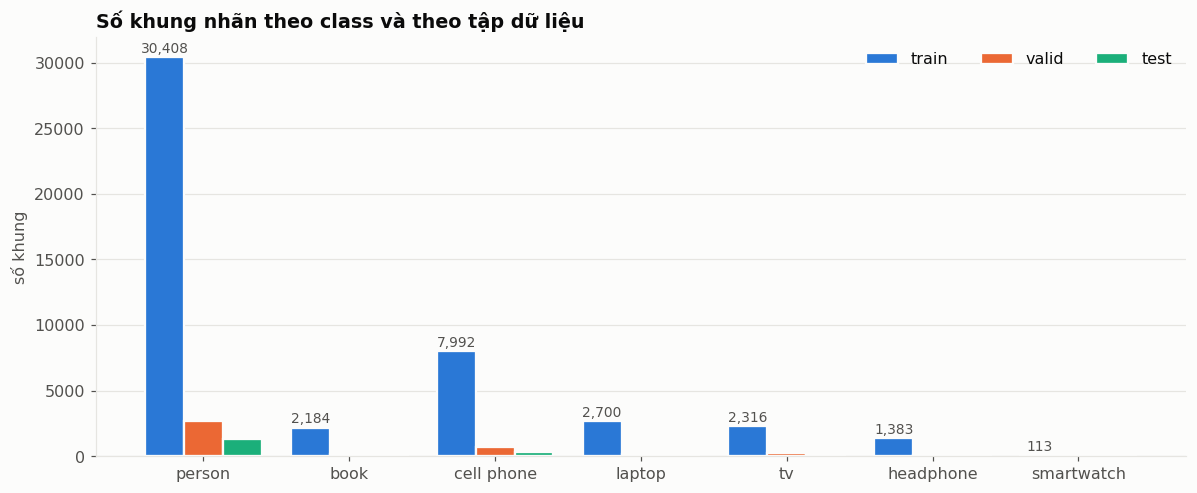

Tỉ lệ class nhiều nhất / ít nhất trong train: 269.1 lần
Cảnh báo: mất cân bằng nặng. Hãy thêm dữ liệu cho class ít nhất hoặc giảm max_images của nguồn lớn.


split,train,valid,test
class,,,
person,30408,2670,1349
book,2184,204,105
cell phone,7992,683,338
laptop,2700,141,87
tv,2316,219,112
headphone,1383,129,86
smartwatch,113,32,18


In [18]:
# Biểu đồ 1: số khung theo class và theo tập
cnt = df.groupby(["class", "split"]).size().unstack(fill_value=0).reindex(CLASSES).fillna(0).astype(int)
cnt = cnt[[s for s in ["train", "valid", "test"] if s in cnt.columns]]

fig, ax = plt.subplots(figsize=(11, 4.6))
grouped_bars(ax, CLASSES, {s: cnt[s].values for s in cnt.columns}, SERIES[:len(cnt.columns)],
             fmt="{:,.0f}", label_idx=[0])          # chỉ ghi số cho tập train
ax.set_title("Số khung nhãn theo class và theo tập dữ liệu")
ax.set_ylabel("số khung")
ax.legend(title=None, ncol=len(cnt.columns))
fig.tight_layout()
save_show(fig, "01_instances_per_class")

tr = cnt["train"]
ratio = tr.max() / max(tr.min(), 1)
print(f"Tỉ lệ class nhiều nhất / ít nhất trong train: {ratio:.1f} lần")
if ratio > 10:
    print("Cảnh báo: mất cân bằng nặng. Hãy thêm dữ liệu cho class ít nhất hoặc giảm max_images của nguồn lớn.")
display(cnt)

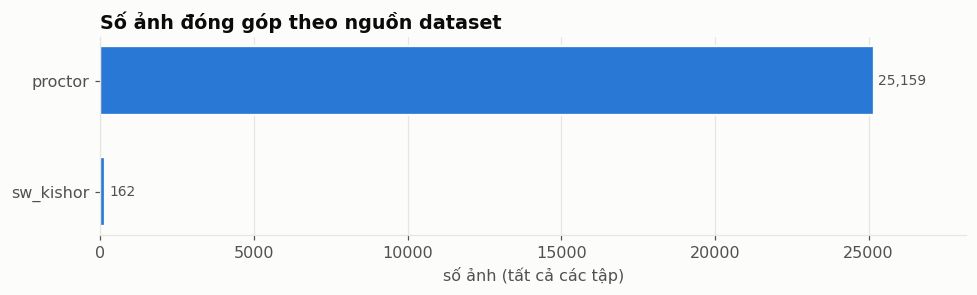

split,test,train,valid
source,,,
proctor,909,22428,1822
sw_kishor,17,113,32


In [19]:
# Biểu đồ 2: số ảnh theo từng nguồn
imgs = df.groupby(["source", "split"])["file"].nunique().unstack(fill_value=0)
tot = imgs.sum(axis=1).sort_values()

fig, ax = plt.subplots(figsize=(9, 0.5 * len(tot) + 1.8))
bars = ax.barh(tot.index, tot.values, color=SERIES[0], edgecolor=SURFACE, linewidth=1.5, height=0.62)
label_bars(ax, bars, "{:,.0f}", horizontal=True)
ax.set_title("Số ảnh đóng góp theo nguồn dataset")
ax.set_xlabel("số ảnh (tất cả các tập)")
ax.set_xlim(0, tot.max() * 1.12)
grid_x(ax)
fig.tight_layout()
save_show(fig, "02_images_per_source")
display(imgs)

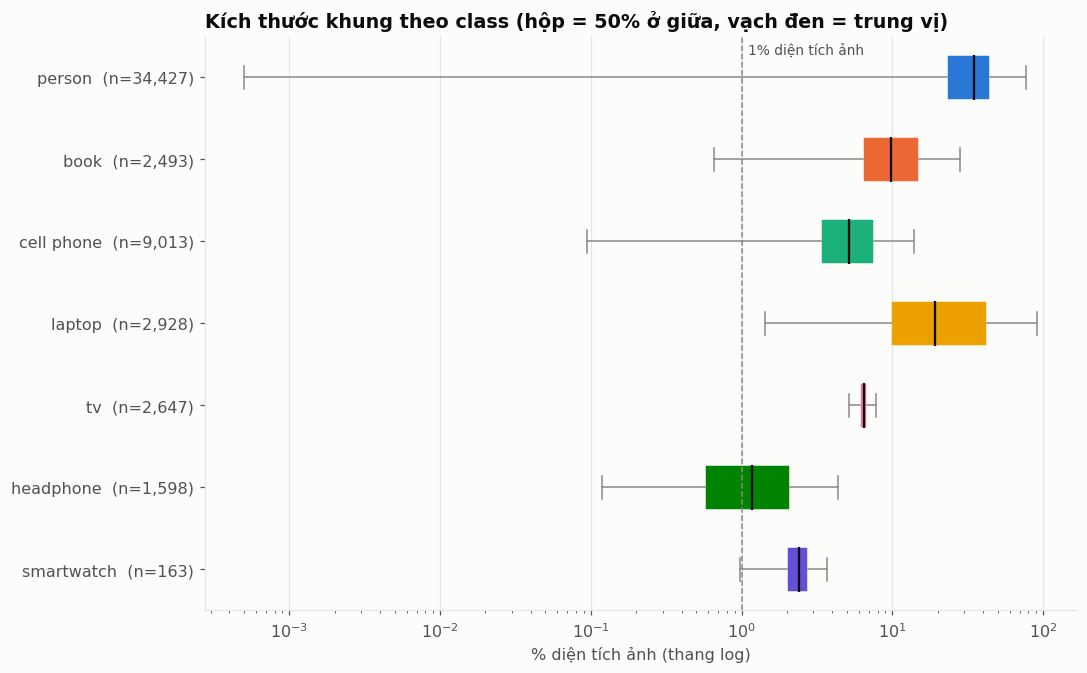

,count,25%,50%,75%
class,,,,
book,2493.0,6.39,9.77,15.08
cell phone,9013.0,3.37,5.14,7.57
headphone,1598.0,0.57,1.17,2.10
laptop,2928.0,9.76,19.21,42.24
person,34427.0,23.17,34.63,44.82
smartwatch,163.0,2.01,2.40,2.78
tv,2647.0,6.15,6.46,6.82


In [20]:
# Biểu đồ 3: phân bố kích thước khung (phần trăm diện tích ảnh), thang log
order = [c for c in CLASSES if (df["class"] == c).any()]
data = [df.loc[df["class"] == c, "area_pct"].values for c in order]

fig, ax = plt.subplots(figsize=(10, 0.62 * len(order) + 1.9))
hboxplot(ax, data, [CLASS_COLOR[c] for c in order])
ax.set_xscale("log")
ax.set_yticks(range(1, len(order) + 1))
ax.set_yticklabels([f"{c}  (n={len(d):,})" for c, d in zip(order, data)])
ax.axvline(1, color=MUTED, ls="--", lw=1)
ax.annotate("1% diện tích ảnh", xy=(1, 1), xycoords=("data", "axes fraction"), xytext=(4, -12),
            textcoords="offset points", fontsize=9, color=INK2)
ax.set_title("Kích thước khung theo class (hộp = 50% ở giữa, vạch đen = trung vị)")
ax.set_xlabel("% diện tích ảnh (thang log)")
fig.tight_layout()
save_show(fig, "03_bbox_size")
display(df.groupby("class")["area_pct"].describe()[["count", "25%", "50%", "75%"]].round(2))

## 4. Train

Mỗi model trong `MODELS` được fine-tune từ trọng số pretrained COCO. Kết quả lưu ở `/kaggle/working/CV/output`. Kaggle không giữ file giữa các phiên: nếu muốn tiếp tục từ lần trước, Add Input là Output của notebook cũ (hoặc một Kaggle Dataset chứa thư mục `CV/output`), notebook sẽ tự sao chép model đã train sang và bỏ qua bước train (đặt `RETRAIN = True` để train lại).


In [21]:
def restore_run(name):
    """Nếu đã có run cũ trong /kaggle/input (Output của notebook trước), sao chép về OUT_DIR."""
    pats = [f"{INPUT_DIR}/*/CV/output/{name}/weights/best.pt",
            f"{INPUT_DIR}/*/*/CV/output/{name}/weights/best.pt",
            f"{INPUT_DIR}/*/*/*/CV/output/{name}/weights/best.pt"]
    for pat in pats:
        for hit in sorted(glob.glob(pat)):
            run = os.path.dirname(os.path.dirname(hit))
            print(f"Sao chép run cũ từ {run}")
            shutil.copytree(run, f"{OUT_DIR}/{name}", dirs_exist_ok=True)
            return True
    return False


runs = {}
for weights in MODELS:
    tag = weights.replace(".pt", "")
    name = f"{tag}_7cls{SUFFIX}"
    best = f"{OUT_DIR}/{name}/weights/best.pt"
    if not os.path.exists(best) and not RETRAIN:
        restore_run(name)
    if os.path.exists(best) and not RETRAIN:
        print(f"[{tag}] đã có best.pt, bỏ qua train (đặt RETRAIN = True để train lại)")
        runs[tag] = f"{OUT_DIR}/{name}"
        continue
    t0 = time.time()
    model = YOLO(weights)
    model.train(
        data=f"{MERGED_DIR}/data.yaml",
        epochs=2 if QUICK_TEST else EPOCHS,
        fraction=0.1 if QUICK_TEST else 1.0,
        imgsz=IMGSZ, batch=BATCH, device=DEVICE, patience=20,
        project=OUT_DIR, name=name, exist_ok=True,
        cache=CACHE, workers=WORKERS,
        hsv_h=0.015, hsv_s=0.6, hsv_v=0.4, degrees=5, translate=0.1, scale=0.4,
        fliplr=0.5, mosaic=1.0, close_mosaic=1 if QUICK_TEST else 10,
    )
    runs[tag] = str(model.trainer.save_dir)
    print(f"[{tag}] train xong sau {(time.time() - t0) / 60:.1f} phút, lưu tại {runs[tag]}")


[yolo26n] đã có best.pt, bỏ qua train (đặt RETRAIN = True để train lại)


## 5. Biểu đồ huấn luyện (biểu đồ 4 và 5)

Cách đọc: train loss giảm đều là bình thường. Nếu val loss bắt đầu tăng trong khi train loss vẫn giảm thì model đang overfit, nên dừng sớm hoặc thêm dữ liệu. Đường đứt đứng đánh dấu epoch có mAP50-95 cao nhất, đó là epoch được lưu thành `best.pt`.

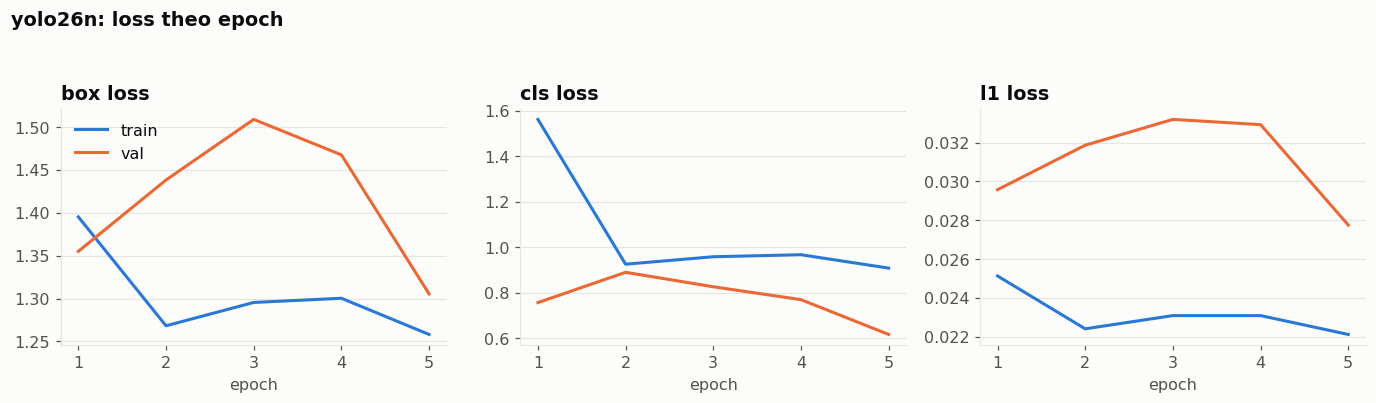

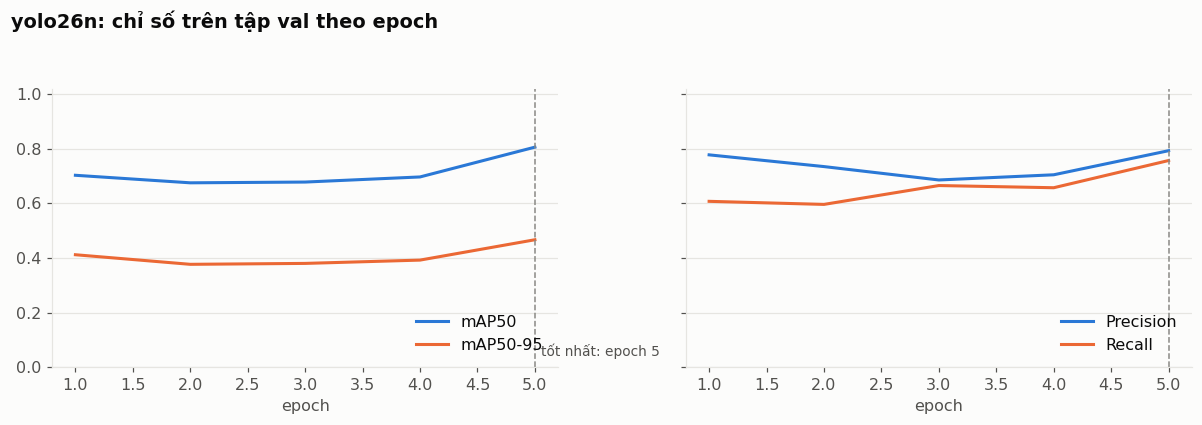

In [22]:
def plot_training(tag, run_dir):
    res = pd.read_csv(f"{run_dir}/results.csv")
    res.columns = [c.strip() for c in res.columns]

    # Biểu đồ 4: loss
    kinds = sorted({c.split("/")[1] for c in res.columns if c.startswith("train/") and c.endswith("loss")})
    fig, axes = plt.subplots(1, len(kinds), figsize=(4.2 * len(kinds), 3.7), squeeze=False)
    for ax, k in zip(axes[0], kinds):
        ax.plot(res["epoch"], res[f"train/{k}"], color=SERIES[0], lw=2, label="train")
        if f"val/{k}" in res:
            ax.plot(res["epoch"], res[f"val/{k}"], color=SERIES[1], lw=2, label="val")
        ax.set_title(k.replace("_", " "))
        ax.set_xlabel("epoch")
        grid_y(ax)
    axes[0][0].legend()
    fig.suptitle(f"{tag}: loss theo epoch", x=0.01, ha="left", fontweight="bold")
    fig.tight_layout(rect=[0, 0, 1, 0.93])
    save_show(fig, f"04_{tag}_loss")

    # Biểu đồ 5: chỉ số theo epoch
    col = {"mAP50": "metrics/mAP50(B)", "mAP50-95": "metrics/mAP50-95(B)",
           "Precision": "metrics/precision(B)", "Recall": "metrics/recall(B)"}
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.9), sharey=True)
    for ax, names in ((axes[0], ["mAP50", "mAP50-95"]), (axes[1], ["Precision", "Recall"])):
        for n, c in zip(names, SERIES[:2]):
            if col[n] in res:
                ax.plot(res["epoch"], res[col[n]], color=c, lw=2, label=n)
        ax.set_xlabel("epoch")
        ax.set_ylim(0, 1.02)
        ax.legend(loc="lower right")
        grid_y(ax)
    if col["mAP50-95"] in res:
        ep = res.loc[res[col["mAP50-95"]].idxmax(), "epoch"]
        for ax in axes:
            ax.axvline(ep, color=MUTED, ls="--", lw=1)
        axes[0].annotate(f"tốt nhất: epoch {int(ep)}", (ep, 0.03), xytext=(4, 2), textcoords="offset points",
                         ha="left", fontsize=9, color=INK2)
    fig.suptitle(f"{tag}: chỉ số trên tập val theo epoch", x=0.01, ha="left", fontweight="bold")
    fig.tight_layout(rect=[0, 0, 1, 0.93])
    save_show(fig, f"05_{tag}_metrics_by_epoch")


for tag, run_dir in runs.items():
    plot_training(tag, run_dir)

### Biểu đồ gốc của Ultralytics (results.png)

Ultralytics tự vẽ ảnh tổng hợp các đường loss, precision, recall, mAP sau khi train và lưu trong thư mục kết quả. Ô dưới mở ảnh đó ra, kèm đường làm mượt (smooth) để dễ nhìn xu hướng.

In [23]:
for tag, run_dir in runs.items():
    p = f"{run_dir}/results.png"
    if os.path.exists(p):
        print(p)
        display(IPImage(p, width=950))
    else:
        print(f"[{tag}] không thấy results.png trong {run_dir}")

[yolo26n] không thấy results.png trong /kaggle/working/CV/output/yolo26n_7cls


## 6. Đánh giá trên tập test

Mỗi model được đánh giá hai lần: một lần với `conf=0.001` (chuẩn để tính mAP) và một lần với `conf=0.25` (ngưỡng thực tế dùng trong hệ thống, để vẽ ma trận nhầm lẫn). Precision, Recall, F1 theo class lấy tại ngưỡng confidence cho F1 cao nhất.

In [24]:
def sample_images(n=300, seed=0):
    files = sorted(glob.glob(f"{MERGED_DIR}/{EVAL_DIR}/images/*.*"))
    random.Random(seed).shuffle(files)
    return files[:n]


def cpu_latency(m, n=15):
    files = sample_images(n + 2)
    m.predict(files[:2], device="cpu", imgsz=IMGSZ, verbose=False)      # khởi động
    t0 = time.time()
    m.predict(files[2:], device="cpu", imgsz=IMGSZ, verbose=False)
    return (time.time() - t0) / max(len(files) - 2, 1) * 1000


def run_eval(tag, run_dir):
    m = YOLO(f"{run_dir}/weights/best.pt")
    common = dict(data=f"{MERGED_DIR}/data.yaml", split=EVAL_SPLIT, imgsz=IMGSZ, iou=0.6, plots=True,
                  project=OUT_DIR, exist_ok=True, verbose=False)
    met = m.val(conf=0.001, name=f"{tag}_eval{SUFFIX}", **common)
    met_cm = m.val(conf=0.25, name=f"{tag}_eval_conf025{SUFFIX}", **common)

    ids = [int(i) for i in met.box.ap_class_index]
    tab = pd.DataFrame({
        "class": [m.names[i] for i in ids],
        "P": np.asarray(met.box.p), "R": np.asarray(met.box.r), "F1": np.asarray(met.box.f1),
        "AP50": np.asarray(met.box.ap50), "AP50-95": np.asarray(met.box.ap),
    }).set_index("class").reindex(CLASSES)
    n_inst = df[df["split"] == EVAL_DIR]["class"].value_counts()
    tab.insert(0, "n_khung", [int(n_inst.get(c, 0)) for c in CLASSES])
    missing = tab.index[tab["AP50"].isna()].tolist()
    if missing:
        print(f"[{tag}] không có khung nhãn trong tập {EVAL_DIR} cho: {missing}")
    tab = tab.fillna(0.0)

    return dict(model=m, met=met, met_cm=met_cm, table=tab,
                params_M=sum(p.numel() for p in m.model.parameters()) / 1e6,
                gpu_ms=float(met.speed["inference"]), cpu_ms=cpu_latency(m))


evals = {tag: run_eval(tag, run_dir) for tag, run_dir in runs.items()}
for tag, ev in evals.items():
    b = ev["met"].box
    print(f"[{tag}] mAP50 = {b.map50:.3f} | mAP50-95 = {b.map:.3f} | P = {b.mp:.3f} | R = {b.mr:.3f}")
    display(ev["table"].round(3))

Ultralytics 8.4.190 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26n summary (fused): 121 layers, 2,391,193 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1318.9±335.5 MB/s, size: 51.8 KB)
val: Scanning /kaggle/temp/merged_dataset/test/labels... 926 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 926/926 1.1Kit/s 0.8s0.0ss
val: New cache created: /kaggle/temp/merged_dataset/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 58/58 6.5it/s 8.9s0.1s
                   all        926       2095      0.798      0.816      0.831      0.454
Speed: 1.1ms preprocess, 3.9ms inference, 0.0ms loss, 1.0ms postprocess per image
Results saved to /kaggle/working/CV/output/yolo26n_eval
Ultralytics 8.4.190 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26n summary (fused): 121 layers, 2,391,193 parameters, 0 gradients, 5.4 GFLOPs
val: Fast imag

,n_khung,P,R,F1,AP50,AP50-95
class,,,,,,
person,1349,0.869,0.960,0.912,0.967,0.638
book,105,0.689,0.933,0.793,0.881,0.499
cell phone,338,0.800,0.873,0.835,0.869,0.404
laptop,87,0.805,0.862,0.833,0.887,0.485
tv,112,0.959,1.000,0.979,0.983,0.789
headphone,86,0.590,0.318,0.414,0.469,0.146
smartwatch,18,0.873,0.767,0.817,0.762,0.217


### Biểu đồ 6 và 7: chỉ số theo class

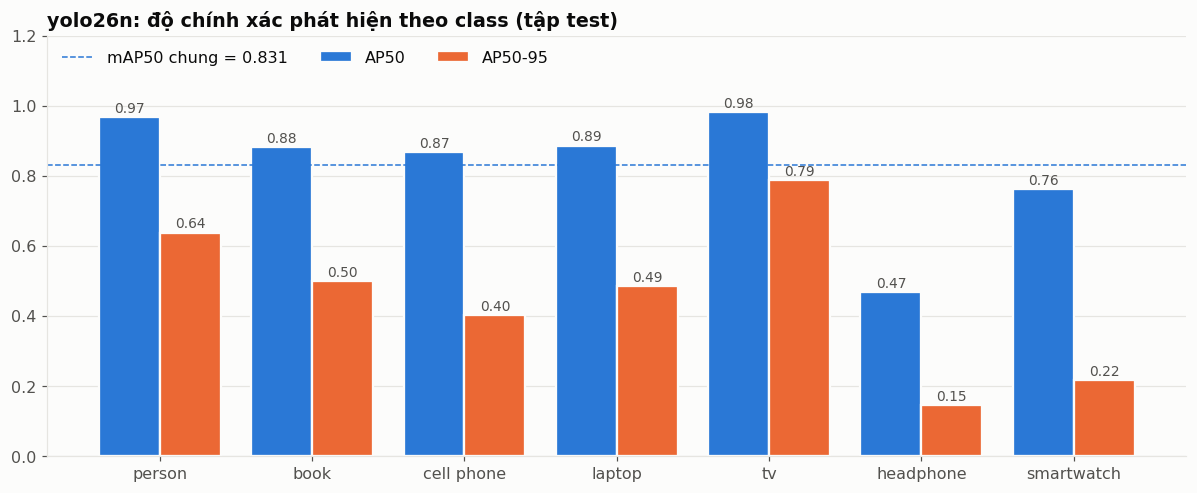

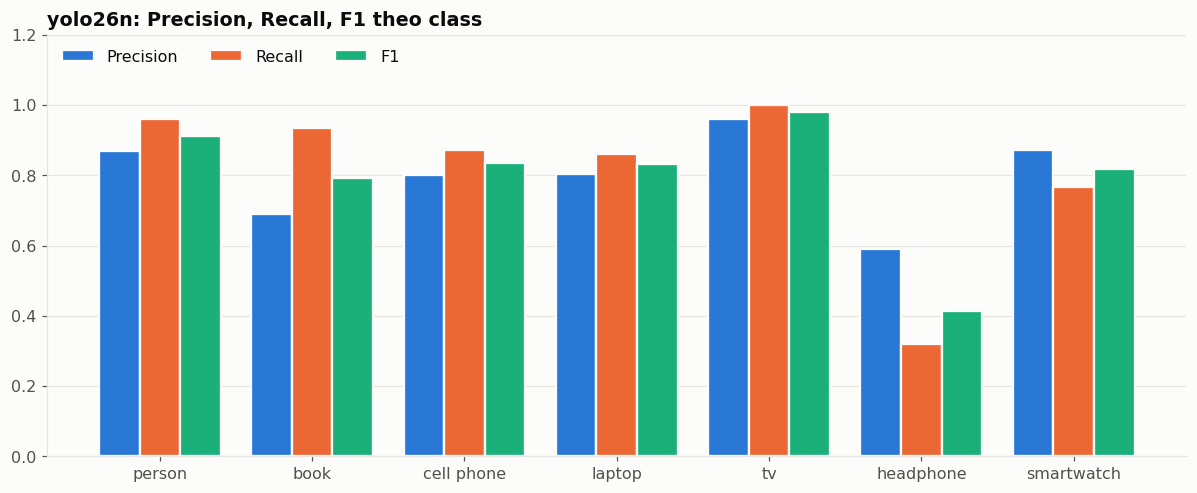

,n_khung,P,R,F1
class,,,,
person,1349,0.869,0.960,0.912
book,105,0.689,0.933,0.793
cell phone,338,0.800,0.873,0.835
laptop,87,0.805,0.862,0.833
tv,112,0.959,1.000,0.979
headphone,86,0.590,0.318,0.414
smartwatch,18,0.873,0.767,0.817


In [25]:
for tag, ev in evals.items():
    tab = ev["table"]

    # Biểu đồ 6: AP50 và AP50-95 theo class
    fig, ax = plt.subplots(figsize=(11, 4.6))
    grouped_bars(ax, CLASSES, {"AP50": tab["AP50"].values, "AP50-95": tab["AP50-95"].values},
                 SERIES[:2], fmt="{:.2f}", label_idx="all")
    ax.axhline(ev["met"].box.map50, color=SERIES[0], ls="--", lw=1, label=f"mAP50 chung = {ev['met'].box.map50:.3f}")
    ax.set_ylim(0, 1.2)
    ax.set_title(f"{tag}: độ chính xác phát hiện theo class (tập {EVAL_DIR})")
    ax.legend(ncol=3, loc="upper left")
    fig.tight_layout()
    save_show(fig, f"06_{tag}_ap_per_class")

    # Biểu đồ 7: Precision, Recall, F1 theo class
    fig, ax = plt.subplots(figsize=(11, 4.6))
    grouped_bars(ax, CLASSES, {"Precision": tab["P"].values, "Recall": tab["R"].values, "F1": tab["F1"].values},
                 SERIES[:3], label_idx=None)
    ax.set_ylim(0, 1.2)
    ax.set_title(f"{tag}: Precision, Recall, F1 theo class")
    ax.legend(ncol=3, loc="upper left")
    fig.tight_layout()
    save_show(fig, f"07_{tag}_prf_per_class")
    display(tab[["n_khung", "P", "R", "F1"]].round(3))

### Biểu đồ 8: ma trận nhầm lẫn

Mỗi cột là một class thật (cộng cột "background" là vùng không có vật), mỗi hàng là class mà model dự đoán, các số đã chuẩn hóa theo cột. Đường chéo càng đậm càng tốt. Ô ở hàng "background" nghĩa là vật thật bị bỏ sót, ô ở cột "background" nghĩa là model báo vật ở chỗ không có gì.

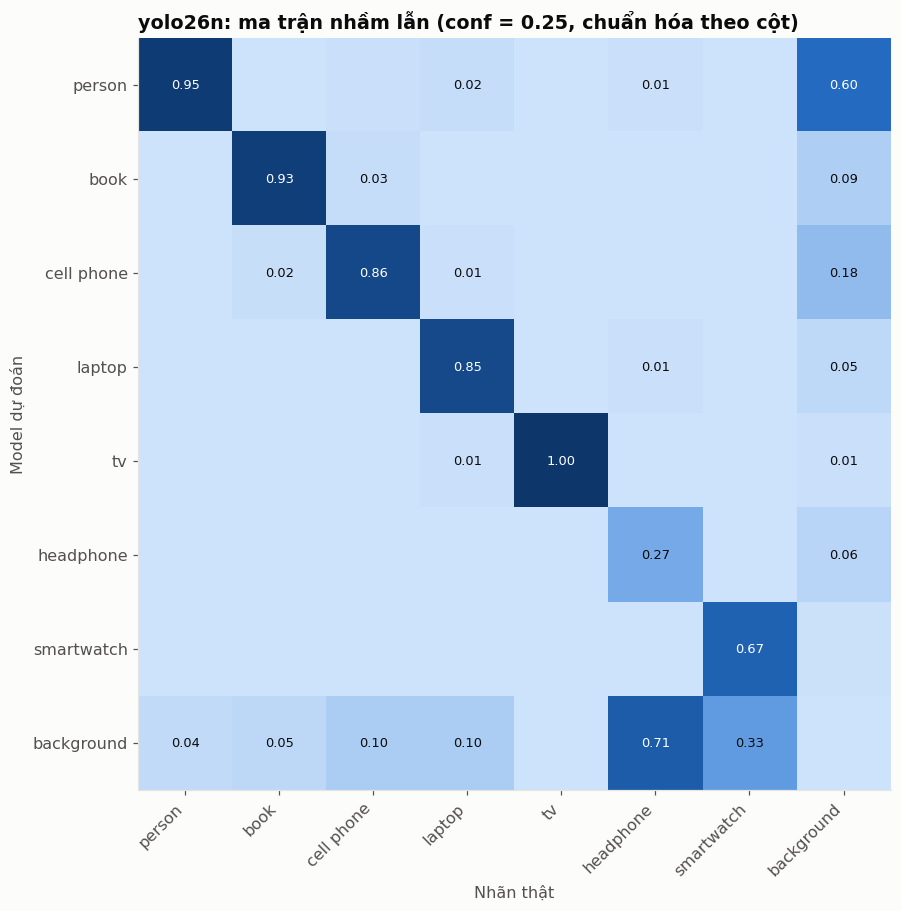

In [26]:
def plot_confusion(tag, ev):
    mat = np.asarray(ev["met_cm"].confusion_matrix.matrix, dtype=float)
    norm = mat / (mat.sum(0, keepdims=True) + 1e-9)
    labels = [ev["model"].names[i] for i in range(len(mat) - 1)] + ["background"]
    cmap = LinearSegmentedColormap.from_list("seq", ["#cde2fb", "#2a78d6", "#0d366b"])

    fig, ax = plt.subplots(figsize=(0.95 * len(labels) + 2, 0.85 * len(labels) + 1.6))
    ax.imshow(norm, cmap=cmap, vmin=0, vmax=1)
    ax.grid(False)
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=45, ha="right")
    ax.set_yticks(range(len(labels)))
    ax.set_yticklabels(labels)
    ax.set_xlabel("Nhãn thật")
    ax.set_ylabel("Model dự đoán")
    for i in range(len(labels)):
        for j in range(len(labels)):
            v = norm[i, j]
            if v >= 0.01:
                ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8.5,
                        color="white" if v > 0.5 else INK)
    ax.set_title(f"{tag}: ma trận nhầm lẫn (conf = 0.25, chuẩn hóa theo cột)")
    fig.tight_layout()
    save_show(fig, f"08_{tag}_confusion_matrix")


for tag, ev in evals.items():
    plot_confusion(tag, ev)

### Biểu đồ 9 và 10: đường Precision–Recall và F1–Confidence

Hai biểu đồ này do Ultralytics vẽ sẵn. Đường F1–Confidence cho biết ngưỡng confidence tốt nhất (ghi ngay trên tiêu đề biểu đồ, dạng "all classes ... at ..."). Ngưỡng này là con số nên đặt trong hệ thống khi đưa model lên web.

BoxPR_curve.png


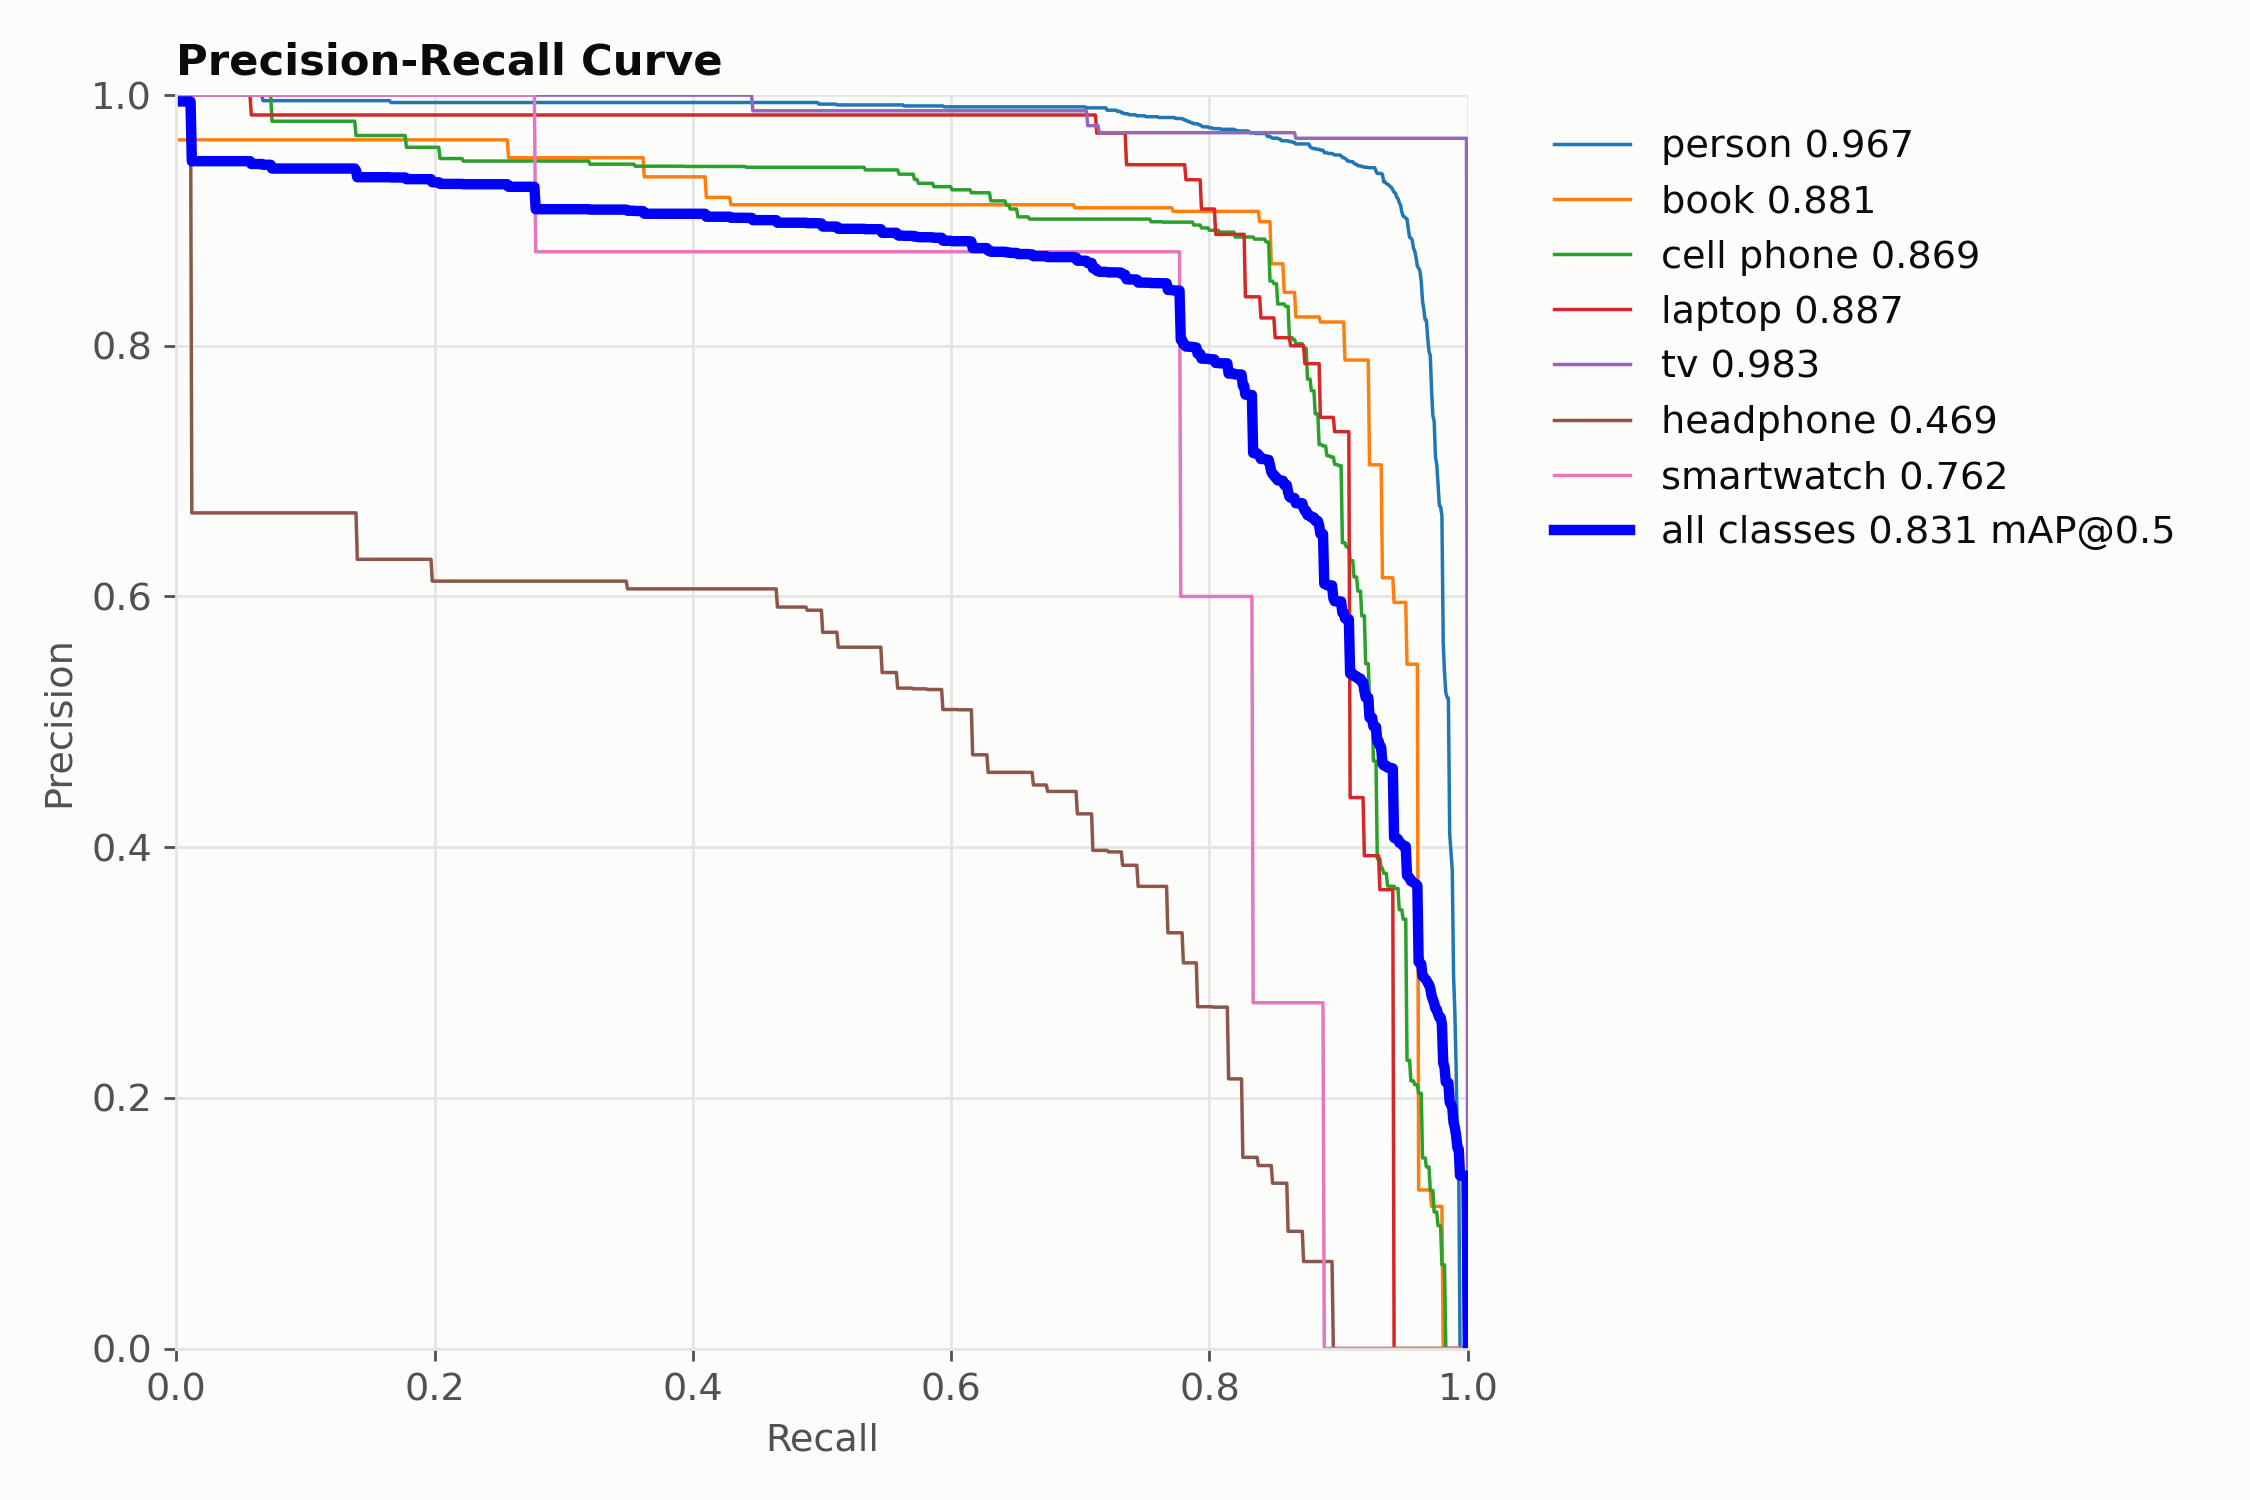

BoxF1_curve.png


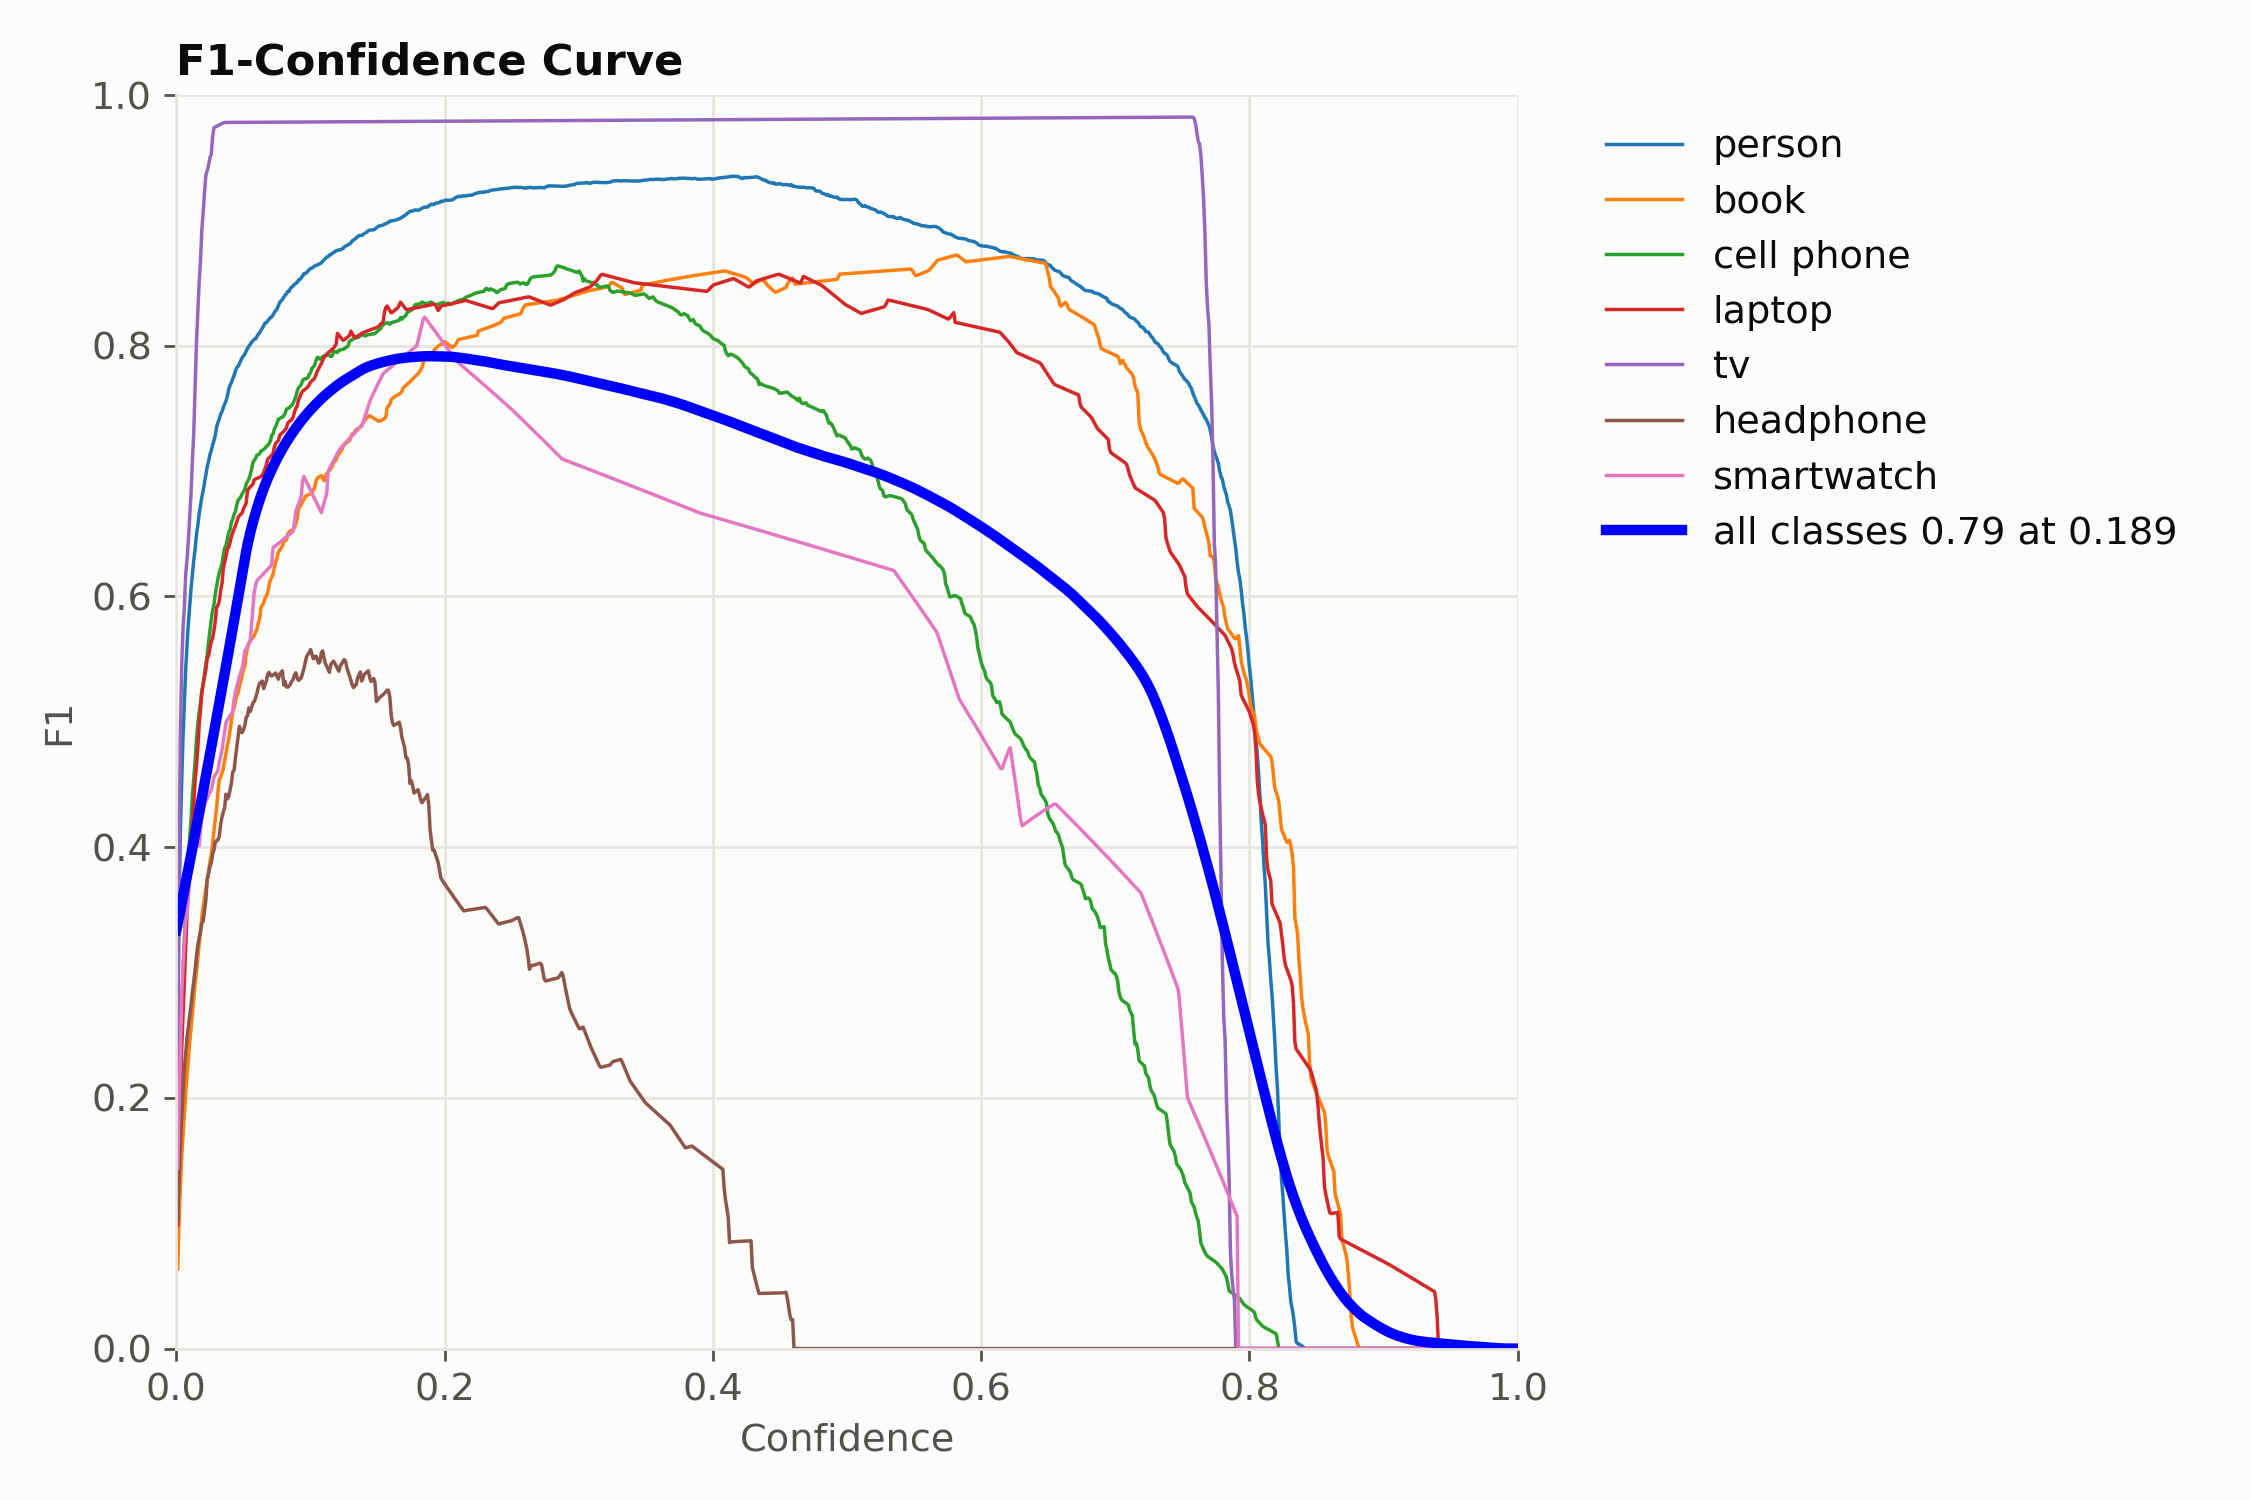

In [27]:
for tag, ev in evals.items():
    save_dir = str(getattr(ev["met"], "save_dir", f"{OUT_DIR}/{tag}_eval{SUFFIX}"))
    for pat in ("*PR_curve.png", "*F1_curve.png"):
        for p in sorted(glob.glob(f"{save_dir}/{pat}")):
            print(os.path.basename(p))
            display(IPImage(p, width=620))

### Biểu đồ 11: phân bố độ tin cậy dự đoán theo class

Nếu độ tin cậy của một class tập trung thấp (dưới 0.4) thì đặt ngưỡng cao sẽ làm mất class đó. Đây là lý do có thể cần ngưỡng riêng cho từng class.

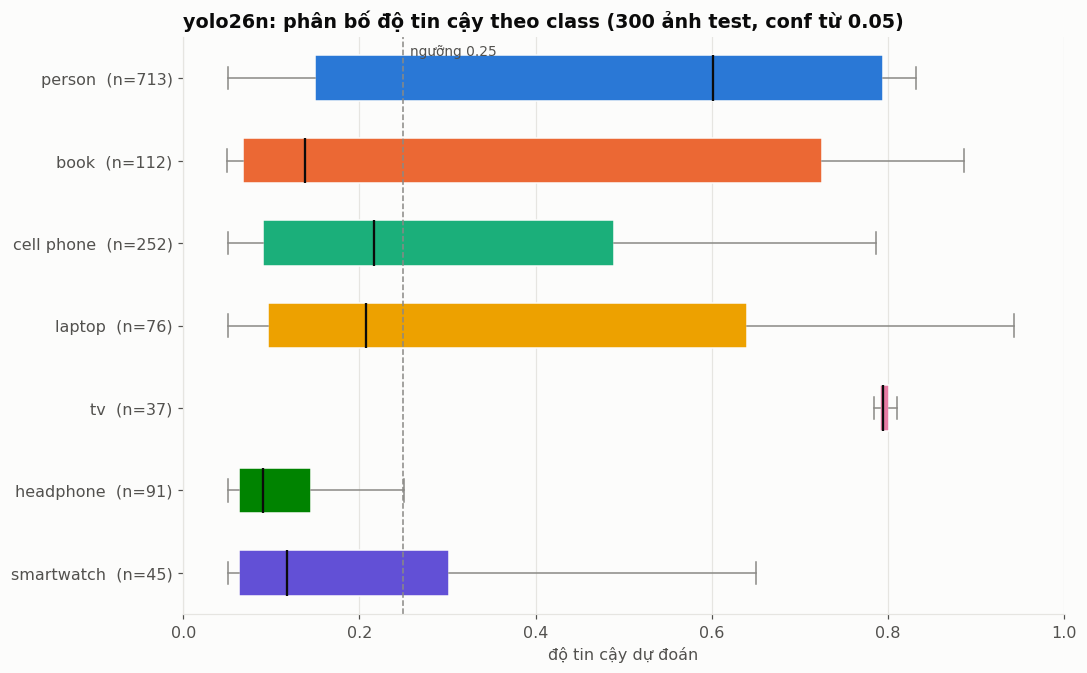

In [28]:
def predict_conf(m, files, conf=0.05):
    rows = []
    for r in m.predict(files, conf=conf, imgsz=IMGSZ, stream=True, verbose=False):
        for c, s in zip(r.boxes.cls.tolist(), r.boxes.conf.tolist()):
            rows.append((m.names[int(c)], s))
    return pd.DataFrame(rows, columns=["class", "conf"])


for tag, ev in evals.items():
    pc = predict_conf(ev["model"], sample_images(300))
    order = [c for c in CLASSES if (pc["class"] == c).any()]
    if not order:
        print(f"[{tag}] không có dự đoán nào để vẽ")
        continue
    data = [pc.loc[pc["class"] == c, "conf"].values for c in order]
    fig, ax = plt.subplots(figsize=(10, 0.62 * len(order) + 1.9))
    hboxplot(ax, data, [CLASS_COLOR[c] for c in order])
    ax.set_yticks(range(1, len(order) + 1))
    ax.set_yticklabels([f"{c}  (n={len(d):,})" for c, d in zip(order, data)])
    ax.axvline(0.25, color=MUTED, ls="--", lw=1)
    ax.annotate("ngưỡng 0.25", xy=(0.25, 1), xycoords=("data", "axes fraction"), xytext=(4, -12),
                textcoords="offset points", fontsize=9, color=INK2)
    ax.set_xlim(0, 1)
    ax.set_xlabel("độ tin cậy dự đoán")
    ax.set_title(f"{tag}: phân bố độ tin cậy theo class (300 ảnh test, conf từ 0.05)")
    fig.tight_layout()
    save_show(fig, f"11_{tag}_confidence_distribution")

### Biểu đồ 12: ảnh dự đoán mẫu

Mỗi class lấy 2 ảnh test có chứa class đó. Xem trực tiếp để biết model bỏ sót, nhầm class hay vẽ khung lệch ở đâu.

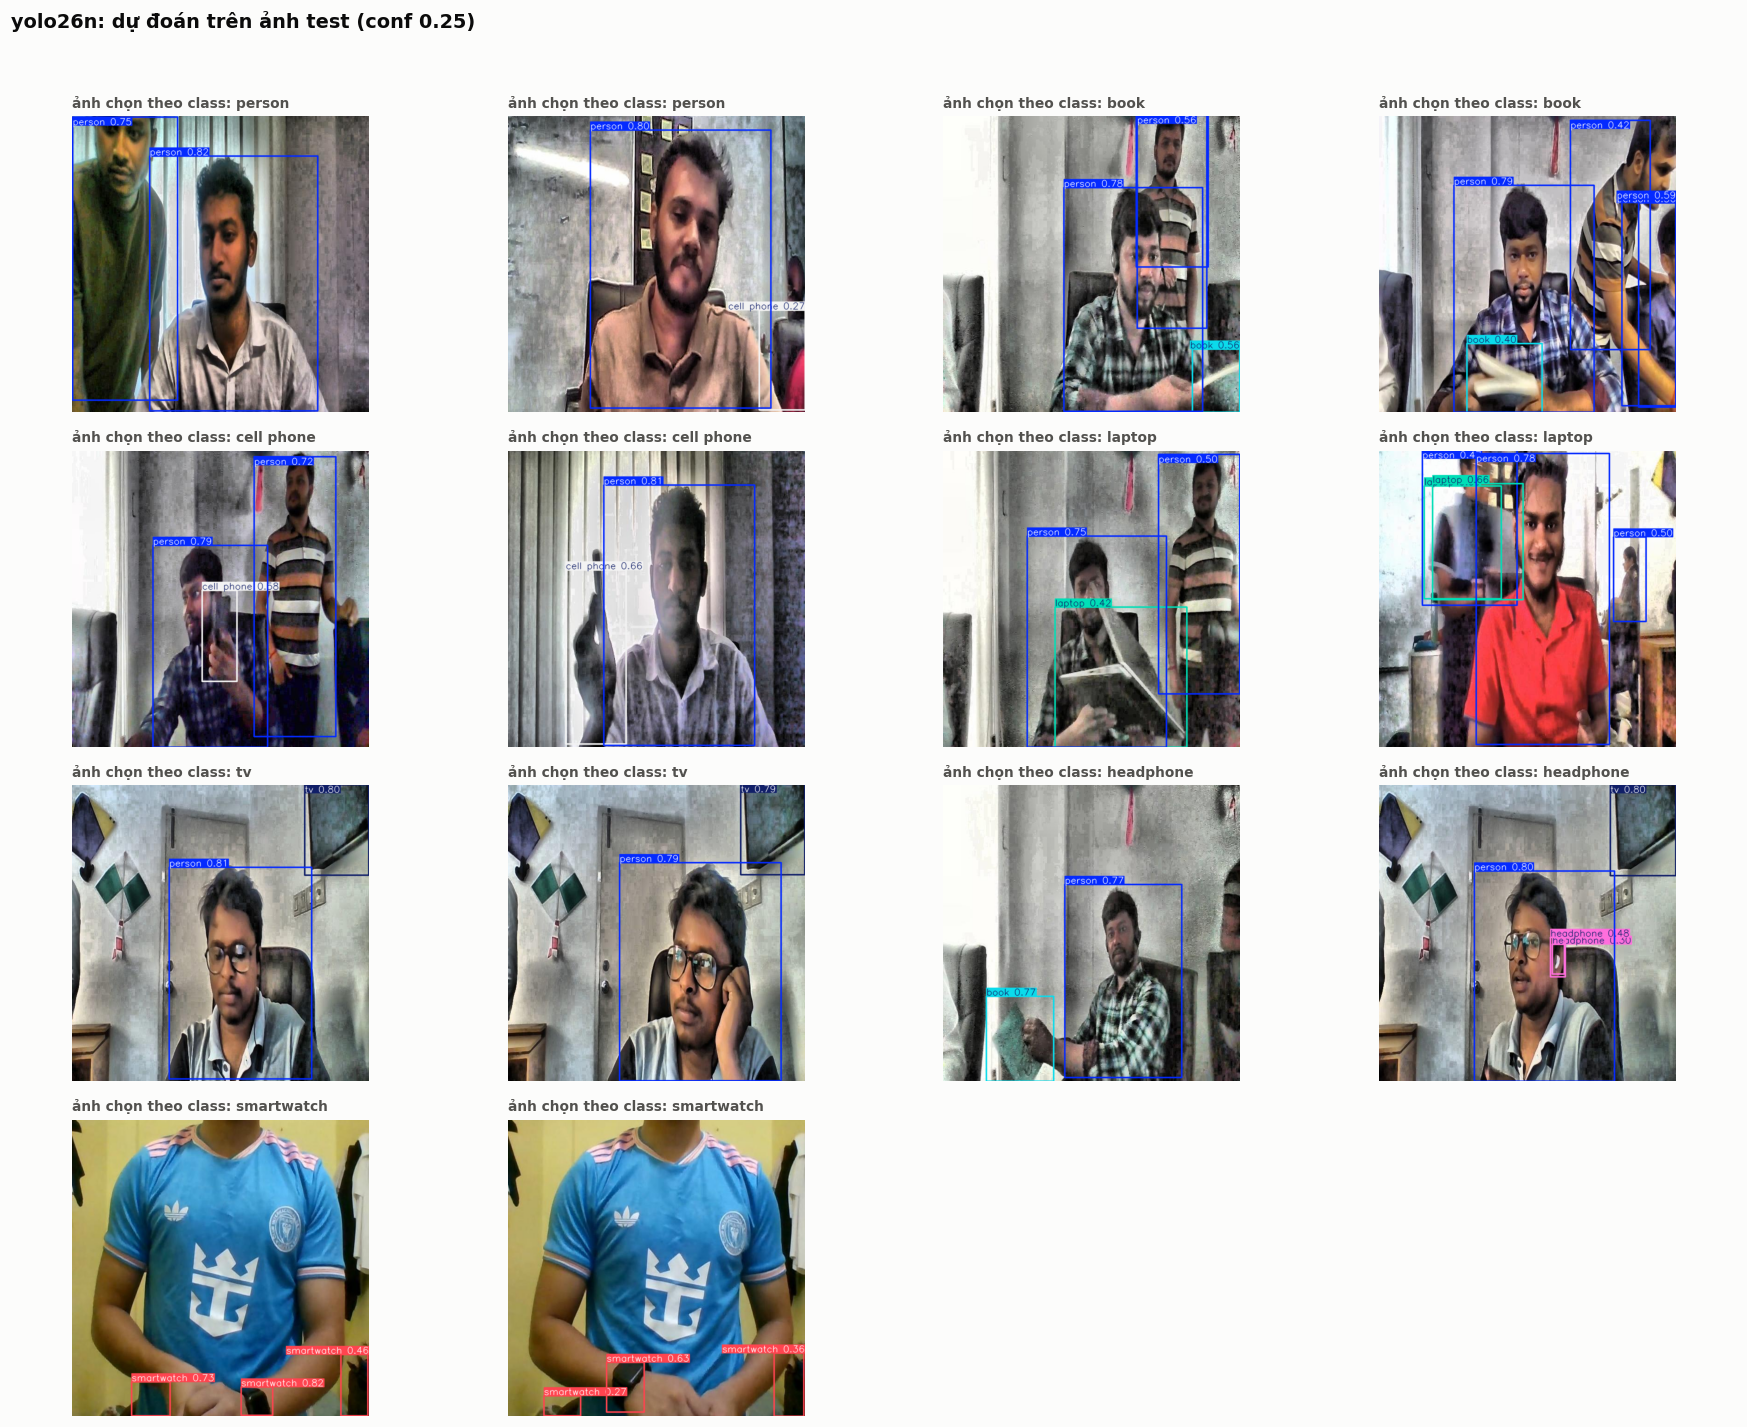

In [29]:
def gallery(tag, m, per_class=2):
    picks = []
    for c in CLASSES:
        stems = df[(df["split"] == EVAL_DIR) & (df["class"] == c)]["file"].drop_duplicates().tolist()
        random.Random(1).shuffle(stems)
        for s in stems[:per_class]:
            if s not in [p[1] for p in picks]:
                picks.append((c, s))
    paths = []
    for c, s in picks:
        found = glob.glob(f"{MERGED_DIR}/{EVAL_DIR}/images/{s}.*")
        paths.append(found[0] if found else None)
    picks = [p for p, f in zip(picks, paths) if f]
    paths = [f for f in paths if f]
    if not paths:
        print("Không tìm thấy ảnh mẫu")
        return
    results = m.predict(paths, conf=0.25, imgsz=IMGSZ, verbose=False)
    cols = 4
    rws = math.ceil(len(paths) / cols)
    fig, axes = plt.subplots(rws, cols, figsize=(4 * cols, 3.3 * rws), squeeze=False)
    for ax, (c, _), r in zip(axes.flat, picks, results):
        ax.imshow(r.plot()[:, :, ::-1])
        ax.set_title(f"ảnh chọn theo class: {c}", fontsize=9, color=INK2)
        ax.axis("off")
        ax.grid(False)
    for ax in list(axes.flat)[len(paths):]:
        ax.axis("off")
    fig.suptitle(f"{tag}: dự đoán trên ảnh test (conf 0.25)", x=0.01, ha="left", fontweight="bold")
    fig.tight_layout(rect=[0, 0, 1, 0.96])
    save_show(fig, f"12_{tag}_prediction_gallery")


for tag, ev in evals.items():
    gallery(tag, ev["model"])

## 7. So sánh (biểu đồ 13 và 14)

**Biểu đồ 13** so model COCO pretrained gốc với model đã fine-tune trên cùng tập test. Model COCO không có class `headphone` và `smartwatch` nên điểm của hai class này ở cột "trước" bằng 0 (đó là kết quả thật, không phải lỗi). Với 5 class COCO có sẵn, nhãn được đổi sang ID của COCO để so công bằng.

**Biểu đồ 14** so các model trong `MODELS` về độ chính xác, số tham số và tốc độ. Tốc độ CPU là con số gần nhất với việc chạy trong trình duyệt (WASM), nhưng trình duyệt thường còn chậm hơn.

Ultralytics 8.4.190 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26n summary (fused): 120 layers, 2,408,932 parameters, 0 gradients, 5.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1263.3±314.4 MB/s, size: 49.9 KB)
val: Scanning /kaggle/temp/coco_view/test/labels... 926 images, 17 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 926/926 1.1Kit/s 0.8s.0ss
val: New cache created: /kaggle/temp/coco_view/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 58/58 8.1it/s 7.1s0.1s
                   all        926       1991      0.258      0.194      0.192     0.0805
Speed: 0.9ms preprocess, 4.0ms inference, 0.0ms loss, 1.1ms postprocess per image


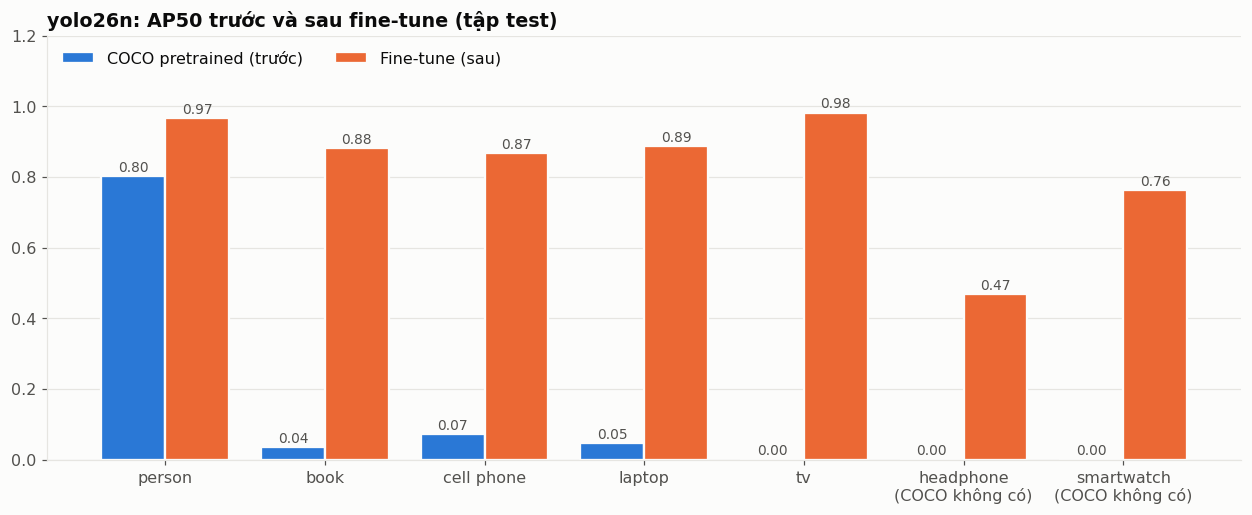

AP50 trung bình trên 5 class COCO có sẵn: trước 0.192 -> sau 0.917
AP50 trung bình trên toàn bộ 7 class: trước 0.137 -> sau 0.831


In [30]:
def baseline_vs_finetuned(tag, weights, ev):
    base = YOLO(weights)                                  # trọng số COCO gốc
    coco = {int(k): v for k, v in base.names.items()}
    inv = {v: k for k, v in coco.items()}
    shared = [c for c in CLASSES if c in inv]
    mapping = {CLASSES.index(c): inv[c] for c in shared}

    root = f"{TEMP_DIR}/coco_view"                           # bản sao tập test với nhãn đổi sang ID COCO
    shutil.rmtree(root, ignore_errors=True)
    os.makedirs(f"{root}/{EVAL_DIR}/images")
    os.makedirs(f"{root}/{EVAL_DIR}/labels")
    for p in glob.glob(f"{MERGED_DIR}/{EVAL_DIR}/images/*.*"):
        dst = f"{root}/{EVAL_DIR}/images/{os.path.basename(p)}"
        try:
            os.link(p, dst)                               # hardlink, không dùng symlink vì Ultralytics resolve đường dẫn
        except OSError:
            shutil.copy2(p, dst)
    for f in glob.glob(f"{MERGED_DIR}/{EVAL_DIR}/labels/*.txt"):
        out = []
        for ln in open(f, encoding="utf-8"):
            q = ln.split()
            if len(q) == 5 and int(q[0]) in mapping:
                out.append(" ".join([str(mapping[int(q[0])])] + q[1:]))
        with open(f"{root}/{EVAL_DIR}/labels/{os.path.basename(f)}", "w", encoding="utf-8") as fh:
            fh.write("\n".join(out) + ("\n" if out else ""))
    rel = f"{EVAL_DIR}/images"
    with open(f"{root}/data.yaml", "w", encoding="utf-8") as fh:
        yaml.safe_dump({"path": root, "train": rel, "val": rel, "test": rel, "names": coco}, fh)

    bm = base.val(data=f"{root}/data.yaml", split=EVAL_SPLIT, imgsz=IMGSZ, conf=0.001, iou=0.6, plots=False,
                  verbose=False, project=OUT_DIR, name=f"{tag}_baseline{SUFFIX}", exist_ok=True)
    ap_base = {coco[int(i)]: float(a) for i, a in zip(bm.box.ap_class_index, bm.box.ap50)}
    before = np.array([ap_base.get(c, 0.0) for c in CLASSES])
    after = ev["table"]["AP50"].values

    mask = np.array([c in inv for c in CLASSES])
    labels = [c if c in inv else f"{c}\n(COCO không có)" for c in CLASSES]
    fig, ax = plt.subplots(figsize=(11.5, 4.8))
    grouped_bars(ax, labels, {"COCO pretrained (trước)": before, "Fine-tune (sau)": after},
                 SERIES[:2], fmt="{:.2f}", label_idx="all")
    ax.set_ylim(0, 1.2)
    ax.set_title(f"{tag}: AP50 trước và sau fine-tune (tập {EVAL_DIR})")
    ax.legend(ncol=2, loc="upper left")
    fig.tight_layout()
    save_show(fig, f"13_{tag}_before_after")
    print(f"AP50 trung bình trên {int(mask.sum())} class COCO có sẵn: trước {before[mask].mean():.3f} -> sau {after[mask].mean():.3f}")
    print(f"AP50 trung bình trên toàn bộ {len(CLASSES)} class: trước {before.mean():.3f} -> sau {after.mean():.3f}")


for weights in MODELS:
    tag = weights.replace(".pt", "")
    baseline_vs_finetuned(tag, weights, evals[tag])

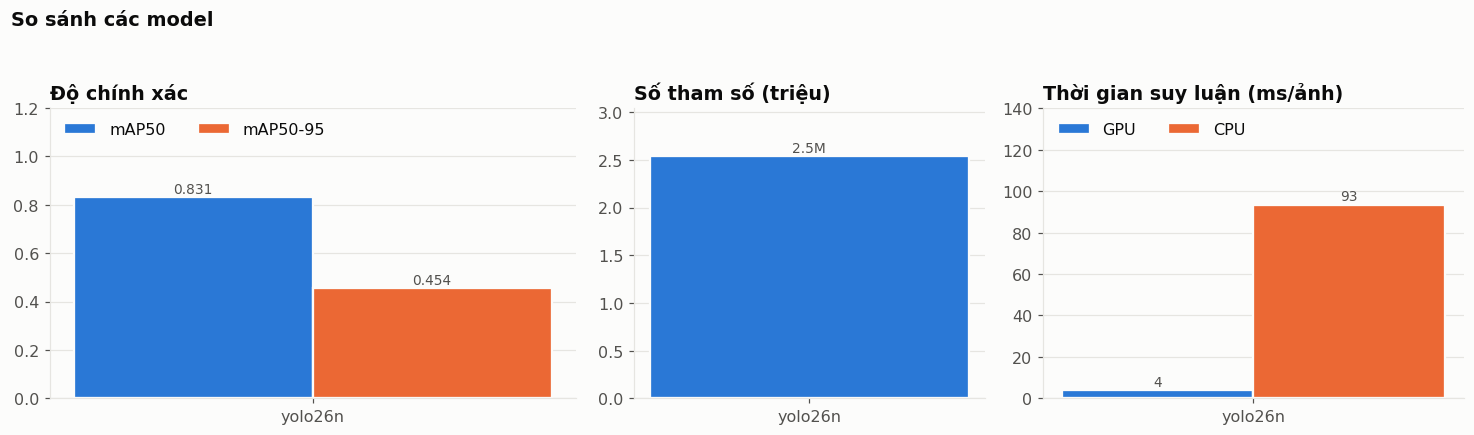

,mAP50,mAP50-95,params_M,GPU ms/ảnh,CPU ms/ảnh
yolo26n,0.831,0.454,2.537,3.896,93.473


In [31]:
summ = pd.DataFrame({
    tag: {"mAP50": ev["met"].box.map50, "mAP50-95": ev["met"].box.map, "params_M": ev["params_M"],
          "GPU ms/ảnh": ev["gpu_ms"], "CPU ms/ảnh": ev["cpu_ms"]}
    for tag, ev in evals.items()
}).T

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.0), gridspec_kw={"width_ratios": [1.5, 1, 1.2]})
grouped_bars(axes[0], list(summ.index), {"mAP50": summ["mAP50"].values, "mAP50-95": summ["mAP50-95"].values},
             SERIES[:2], fmt="{:.3f}", label_idx="all")
axes[0].set_ylim(0, 1.2)
axes[0].set_title("Độ chính xác")
axes[0].legend(ncol=2, loc="upper left")

bars = axes[1].bar(summ.index, summ["params_M"], color=SERIES[0], edgecolor=SURFACE, linewidth=1.5, width=0.55)
label_bars(axes[1], bars, "{:.1f}M")
axes[1].set_ylim(0, summ["params_M"].max() * 1.2)
axes[1].set_title("Số tham số (triệu)")
grid_y(axes[1])

grouped_bars(axes[2], list(summ.index), {"GPU": summ["GPU ms/ảnh"].values, "CPU": summ["CPU ms/ảnh"].values},
             SERIES[:2], fmt="{:.0f}", label_idx="all")
axes[2].set_ylim(0, max(summ["CPU ms/ảnh"].max(), summ["GPU ms/ảnh"].max()) * 1.5)
axes[2].set_title("Thời gian suy luận (ms/ảnh)")
axes[2].legend(ncol=2, loc="upper left")
fig.suptitle("So sánh các model", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.94])
save_show(fig, "14_model_comparison")
display(summ.round(3))

## 8. Export ONNX và lưu kết quả

Model YOLO26 có thiết kế không cần NMS nên dạng đầu ra có thể khác YOLOv8. Ô dưới in ra shape đầu vào và đầu ra của file ONNX để bạn đối chiếu khi viết code đọc kết quả trên web.

In [32]:
os.makedirs(f"{OUT_DIR}/summary{SUFFIX}", exist_ok=True)
for tag, ev in evals.items():
    ev["table"].round(4).to_csv(f"{OUT_DIR}/summary{SUFFIX}/{tag}_per_class.csv", encoding="utf-8-sig")
summ.round(4).to_csv(f"{OUT_DIR}/summary{SUFFIX}/model_comparison.csv", encoding="utf-8-sig")

for tag, run_dir in runs.items():
    m = YOLO(f"{run_dir}/weights/best.pt")
    path = m.export(format="onnx", imgsz=IMGSZ, simplify=True)
    print(f"[{tag}] ONNX: {path}")
    try:
        import onnxruntime as ort
        s = ort.InferenceSession(str(path), providers=["CPUExecutionProvider"])
        print("  input :", [(i.name, i.shape) for i in s.get_inputs()])
        print("  output:", [(o.name, o.shape) for o in s.get_outputs()])
    except Exception as e:
        print("  (bỏ qua kiểm tra ONNX:", e, ")")

print("\nBiểu đồ (PNG):", CHART_DIR)
print("Bảng kết quả (CSV):", f"{OUT_DIR}/summary{SUFFIX}")

Ultralytics 8.4.190 🚀 Python-3.13.15 torch-2.11.0+cu128 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO26n summary (fused): 121 layers, 2,391,193 parameters, 0 gradients, 5.4 GFLOPs

PyTorch: starting from '/kaggle/working/CV/output/yolo26n_7cls/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 11, 8400) (15.0 MB)
requirements: Ultralytics requirements ['onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 12 packages in 383ms
Prepared 2 packages in 437ms
Installed 2 packages in 12ms
 + onnxruntime==1.31.1
 + onnxslim==0.1.98

requirements: AutoUpdate success ✅ 1.4s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.22.0 opset 18...
ONNX: slimming with onnxslim 0.1.98...
ONNX: export success ✅ 